# Session 1 — Python for scientific computing
### Notebooks, NumPy, plots, solving equations, derivatives and integrals

Read each explanation and **run every cell while you read**. Change the numbers, run the cell again, and
look at what happens: this is the fastest way to check that you have understood. When you reach an
exercise, write your answer in the empty cell below it. Ask for help when you do not know what
to do next. The solutions will be given to you after the session.

There are six exercises. You are **not** expected to finish
everything.

## Plan of the session

| | Time | What you will do |
|---|---|---|
| **Getting set up** | 15 min | See how a notebook works. Run your first cell. |
| **Part 1 — Useful basics** | 35 min | Variables, lists, loops, functions. Where to find help. *(Exercise 1.1)* |
| **Part 2 — NumPy and Matplotlib** | 70 min | Arrays and shapes. Your first figures. Linear systems. Newton–Raphson. *(Exercises 2.1 and 2.2)* |
| **Break** | 15 min | In the middle of Part 2. |
| **Part 3 — Differentiation and integration** | 30 min | Derivatives and integrals from values on a grid. *(Exercises 3.1 to 3.3)* |
| **Going further** | — | Two extra topics, if you finish early. |

## Getting set up

A **notebook** is a document made of cells. A cell contains either text (like this one) or code. To
run a code cell, select it and press **Shift + Enter**. The output appears underneath.

Now run this one.


In [1]:
print("Bonjour, bootcamp Python!")

Bonjour, bootcamp Python!


### Order of execution

All the cells share the same memory, and they run **in the order you run them**. This is not always
from top to bottom. You can get a wrong answer with no error message. This is the most common cause
of confusion in a notebook.

Run the next two cells. Then go back, change `n` to `10`, and run only that first cell again. Look
at the output of the second cell: it is still there, but it is old. It was computed with the
previous value of `n`.

When you are not sure of the state of your notebook, restart it and run everything again. On
JupyterCloud this is *Kernel → Restart Kernel and Run All Cells*. Always do this before you submit a notebook. If it does not run
correctly from top to bottom, it is not correct.

In [2]:
n = 3

In [3]:
print("n squared is", n**2)

n squared is 9


---
## Part 1 — Useful basics

The minimum you need to start doing numerical work: variables, operators, lists, loops and
functions.

### Variables and types

In [4]:
x = 3            # an integer (int)
y = 2.5          # a real number (float)
name = "ENPC"    # a string (str)
flag = True      # a boolean (bool): True or False

print(x, y, name, flag)
print(type(x), type(y), type(name), type(flag))

3 2.5 ENPC True
<class 'int'> <class 'float'> <class 'str'> <class 'bool'>


Note two things. There are **no semicolons** at the end of a line. And you do not declare the type
of a variable: Python chooses it from the value you give.

### Operators

In [5]:
a, b = 7, 2              # assign two variables at once

print(a + b, a - b, a * b)
print(a / b)             # 3.5  -- true division, always gives a float
print(a // b)            # 3    -- integer division
print(a % b)             # 1    -- remainder
print(a ** b)            # 49   -- power (NOT ^, which means something else in Python)

print(a > b, a == b, a != b)   # comparisons give booleans

9 5 14
3.5
3
1
49
True False True


### Lists and indexing

In [6]:
L = [1, 2, 3]
L.append(4)              # add an element at the end
print(L, len(L))

# INDEXING STARTS AT 0. This is the most common mistake if you come from MATLAB.
print(L[0])              # 1  -- the first element
print(L[2])              # 3  -- the third
print(L[-1])             # 4  -- the last, counting backwards
print(L[1:3])            # [2, 3]  -- a slice: from index 1 up to (not including) 3

[1, 2, 3, 4] 4
1
3
4
[2, 3]


### Control flow: `if` / `elif` / `else`, and loops

In [7]:
temperature = 22

if temperature < 15:          # note the colon, and the indentation of the block below it
    print("cold")
elif temperature < 25:
    print("mild")
else:
    print("hot")

mild


The indentation is part of the syntax, not just a way to make the code look nice. C uses `{ }` and
MATLAB uses `end`. Python uses a colon, then a block of lines moved to the right.

In [8]:
# 'for' loops over the values of a collection
for value in [10, 20, 30]:
    print(value, "doubled is", 2 * value)

# range(n) produces 0, 1, ..., n-1  -- n values, starting at zero
total = 0
for k in range(1, 11):        # 1, 2, ..., 10   (the upper end is excluded)
    total = total + k
print("1 + 2 + ... + 10 =", total)

# 'while' loops run until their condition becomes False
count = 10
while count > 0:
    count = count - 1
print("count is now", count)

10 doubled is 20
20 doubled is 40
30 doubled is 60
1 + 2 + ... + 10 = 55
count is now 0


### Functions

In [9]:
def f(x):                     # 'def', a name, arguments, colon, indented body
    return x**2 - 2           # 'return' gives the value back

print(f(0), f(1), f(2))

# A function can take several arguments and return several values
def minmax(L):
    return min(L), max(L)

low, high = minmax([4, 1, 9, 2])
print(low, high)

-2 -1 2
1 9


### Importing libraries

Python on its own does very little numerical work. The tools come from **libraries**, and you have
to bring them in. There are two separate steps, and they are easy to confuse.

**`pip install numpy`** puts the library files on the machine. You do this **once per machine**.
Think of it as buying a book and putting it on the shelf. On JupyterCloud it is already done for
you, so the `%pip` line below has nothing to install. It is there so that the notebook also works on
a computer where the libraries are missing.

**`import numpy as np`** takes a library that is already on the machine and loads it into the memory
of *this* notebook, so that you can use it. This is taking the book off the shelf and opening it on
your desk. You have to do it again every time you start or restart the notebook.

`as np` gives the library a short name: you write `np.sqrt` instead of `numpy.sqrt`. Everybody uses
`np` for NumPy and `plt` for Matplotlib, so your code looks like everyone else's.

In [10]:
#%pip install -q --user numpy matplotlib scipy

import numpy as np                   # numerical arrays  -- 'np' is the usual short name
import matplotlib.pyplot as plt      # plotting

print(np.sqrt(2), np.pi, np.exp(1))

1.4142135623730951 3.141592653589793 2.718281828459045


Two error messages tell you which of the two steps is missing:

- `ModuleNotFoundError: No module named 'pandas'` — the library is **not on the machine**. That is a
  `pip` problem.
- `NameError: name 'np' is not defined` — the library is there, but you did **not run the import in
  this notebook**. Run the cell above again. This happens all the time after *Restart Kernel*.

### Finding out how a command works

Nobody remembers the arguments of every function. What matters is finding them quickly. Here are
three ways.

1. Put your cursor between the brackets of a function call and press **Shift + Tab**. The list of
   arguments appears. You do not have to stop writing your code.
2. **`help(np.linspace)`** prints the documentation directly in the notebook. **`np.linspace?`**
   does the same in a side panel.
3. **The official web documentation**, when you need a real explanation and not just a reminder:
   - NumPy: [numpy.org/doc/stable](https://numpy.org/doc/stable/)
   - Matplotlib: the [gallery of examples](https://matplotlib.org/stable/gallery/). Find the
     picture you want, then copy the code under it. This is the fastest way to make a figure.

Documentation pages are long. You do not need to read the whole page. The **Parameters** section
tells you what to give the function. The **Examples** section, at the bottom, is usually the
quickest way to understand it.

In [11]:
help(np.linspace)      # in a notebook you can also just write:  np.linspace?

Help on method descriptor linspace in module numpy:

linspace(
    start,
    stop,
    num=50,
    endpoint=True,
    retstep=False,
    dtype=None,
    axis=0,
    *,
    device=None
)
    Return evenly spaced numbers over a specified interval.

    Returns `num` evenly spaced samples, calculated over the
    interval [`start`, `stop`].

    The endpoint of the interval can optionally be excluded.

    .. versionchanged:: 1.20.0
        Values are rounded towards ``-inf`` instead of ``0`` when an
        integer ``dtype`` is specified. The old behavior can
        still be obtained with ``np.linspace(start, stop, num).astype(np.int_)``

    Parameters
    ----------
    start : array_like
        The starting value of the sequence.
    stop : array_like
        The end value of the sequence, unless `endpoint` is set to False.
        In that case, the sequence consists of all but the last of ``num + 1``
        evenly spaced samples, so that `stop` is excluded.  Note that the step
  

An error message is also documentation. Read it **from the bottom**. The last line tells you what
the problem is. The lines above it tell you which line of your code caused it.

The cell below runs a wrong line on purpose. `try: ... except ...:` catches the error, so the
notebook prints the message and continues instead of stopping. You do not need to write this
yourself today. You will just see it again a few times below.

In [12]:
try:
    np.linspace(0, 1, "ten")        # incorrect on purpose: the third argument must be a number
except TypeError as e:
    print("TypeError:", e)

TypeError: 'str' object cannot be interpreted as an integer


**Exercise 1.1 — a function and a loop.** Write a function `norm2(L)` that takes a list of numbers
and returns $\sqrt{\sum_k L_k^2}$, using a `for` loop to build the sum. Test it on `[3, 4]` — you
should get `5.0`.

💡 *Hint: start the sum at `0`, add `value**2` inside the loop, and take `np.sqrt` of the total at
the end.*

In [13]:
def norm2(L):
    c = 0
    for x in L:
        c += x**2
    return np.sqrt(c)

---
## Part 2 — NumPy and Matplotlib

A list is fine for a few values. For numerical work you use a **NumPy array** instead. It stores
numbers in a compact way, and every operation is applied to the whole array at once, without a loop.
This is called *vectorisation*. It is shorter to write, and much faster to run.

In [14]:
# Creating arrays
a = np.array([1, 2, 3])          # from a list
z = np.zeros(5)                  # five zeros
o = np.ones(3)                   # three ones
g = np.linspace(0, 1, 5)         # 5 evenly spaced points from 0 to 1, both ends included
r = np.arange(0, 10, 2)          # 0 to 10 (excluded), step 2
I = np.eye(3)                    # 3x3 identity matrix

print(a, z, o, g, r, sep="\n")
print(I)

[1 2 3]
[0. 0. 0. 0. 0.]
[1. 1. 1.]
[0.   0.25 0.5  0.75 1.  ]
[0 2 4 6 8]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


⚠️ **A Python list is not a NumPy array.** The same operator does two different things:

In [15]:
L = [1, 2, 3]
a = np.array([1, 2, 3])

print(L * 2)    # [1, 2, 3, 1, 2, 3]   -- repeats the LIST
print(a * 2)    # [2 4 6]              -- multiplies each ELEMENT

[1, 2, 3, 1, 2, 3]
[2 4 6]


In [16]:
# Evaluate a function everywhere at once -- no loop
x = np.linspace(0, 2*np.pi, 100)
y = np.sin(x)

print(y.shape)                 # (100,) -- one value per grid point
print("mean:", np.mean(y))
print("max: ", np.max(y))
print("sum: ", np.sum(y))

(100,)
mean: -1.5771969893796585e-17
max:  0.9998741276738751
sum:  -1.5771969893796585e-15


### A first plot

You now have 100 values. To see how the function behaves, draw it. This is what Matplotlib is for.

Always put a title and a label on each axis.

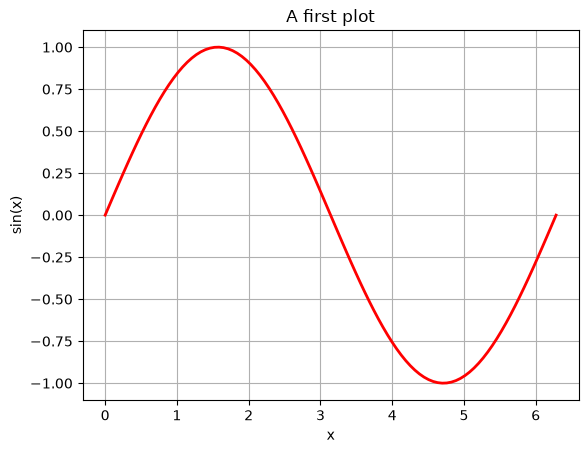

In [17]:
plt.figure()                              # start a new figure
plt.plot(x, y, 'r-', linewidth=2)         # 'r-' = red solid line
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("A first plot")
plt.grid(True)
plt.show()

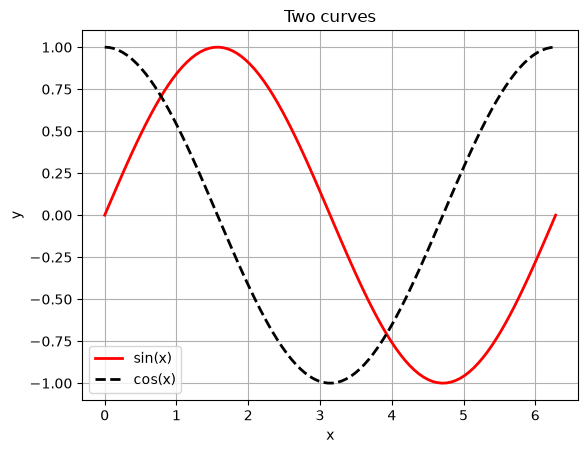

In [18]:
# Several curves on the same figure, with a legend
plt.figure()
plt.plot(x, np.sin(x), 'r-',  linewidth=2, label="sin(x)")
plt.plot(x, np.cos(x), 'k--', linewidth=2, label="cos(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Two curves")
plt.legend()
plt.grid(True)
plt.show()

### Shapes

Every NumPy array has a **shape**: its number of rows, of columns, and so on. Most errors in
numerical code are shape errors. When a result is not what you expected, print the shape first.

In [19]:
a = np.arange(12)
print(a, a.shape)

M = a.reshape(3, 4)          # the same 12 numbers, arranged as 3 rows of 4
print(M)
print(M.shape, M.T.shape)    # .T is the transpose: 3x4 becomes 4x3

[ 0  1  2  3  4  5  6  7  8  9 10 11] (12,)
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(3, 4) (4, 3)


### Broadcasting

Broadcasting lets NumPy combine two arrays that do **not** have the same shape.

You have already used it. In `a * 2` above, the number `2` was used for every element of `a`. NumPy
repeats the smaller one as many times as needed, so that you do not write a loop.

**The rule.** Write the two shapes one above the other, aligned **on the right**. A missing position
counts as 1. Then compare them position by position:

- the two numbers are **equal** → nothing to do;
- one of them is **1** → that array is repeated in this direction;
- they are **different and neither is 1** → NumPy gives an error.

```
(3, 1)     a column of 3 numbers
(1, 4)     a row of 4 numbers
------
(3, 4)     the result
```

In [20]:
# the simplest case: an array and a single number
a = np.array([10, 20, 30])
print(a * 2)                      # the 2 is used for all three elements

# a column and a row
col = np.array([[1],
                [2],
                [3]])             # shape (3, 1)
row = np.array([1, 2, 3, 4])      # shape (4,)
print(col.shape, row.shape)

print(col * row)                  # shape (3, 4): the multiplication table, without a loop

[20 40 60]
(3, 1) (4,)
[[ 1  2  3  4]
 [ 2  4  6  8]
 [ 3  6  9 12]]


The same rule works between a **matrix** and a single row or column. This is how you work on all
the columns of a table at once, or on all the rows. It is the most common use of broadcasting.

In [21]:
data = np.array([[ 1.0,  2.0,  3.0],
                 [ 4.0,  5.0,  6.0],
                 [ 7.0,  8.0,  9.0],
                 [10.0, 11.0, 12.0]])

print(data)
print("shape:", data.shape)        # 4 rows, 3 columns

[[ 1.  2.  3.]
 [ 4.  5.  6.]
 [ 7.  8.  9.]
 [10. 11. 12.]]
shape: (4, 3)


First you need one value per column, or one value per row. This is what the `axis` argument is for,
and it works the same way for every operation of this kind: `mean`, `sum`, `max`, `min`, `std`.

- **`axis=0`** goes **down the rows**. You get one value per column, so shape `(3,)`.
- **`axis=1`** goes **across the columns**. You get one value per row, so shape `(4,)`.
- With **no `axis`**, the whole array is reduced to a single number.

In [22]:
print("over everything:", np.max(data))          # no axis: one single number

print("\nmean per column:", np.mean(data, axis=0))
print("sum  per column:", np.sum(data, axis=0))
print("max  per column:", np.max(data, axis=0))
print("shape:", np.mean(data, axis=0).shape)     # (3,) -- one value per column

over everything: 12.0

mean per column: [5.5 6.5 7.5]
sum  per column: [22. 26. 30.]
max  per column: [10. 11. 12.]
shape: (3,)


In [23]:
print("mean per row:", np.mean(data, axis=1))
print("sum  per row:", np.sum(data, axis=1))
print("max  per row:", np.max(data, axis=1))
print("shape:", np.mean(data, axis=1).shape)     # (4,) -- one value per row

mean per row: [ 2.  5.  8. 11.]
sum  per row: [ 6. 15. 24. 33.]
max  per row: [ 3.  6.  9. 12.]
shape: (4,)


Now combine the table with one of these. Removing the mean of each **column** works directly:
shapes `(4, 3)` and `(3,)`, so the row of means is repeated 4 times downwards.

In [24]:
means = np.mean(data, axis=0)      # one mean per column, shape (3,)
print(data - means)
print("mean of each column afterwards:", np.mean(data - means, axis=0))

[[-4.5 -4.5 -4.5]
 [-1.5 -1.5 -1.5]
 [ 1.5  1.5  1.5]
 [ 4.5  4.5  4.5]]
mean of each column afterwards: [0. 0. 0.]


Now try the same thing with the **rows**: divide each row by its own sum. This does not work.

In [25]:
sums = np.sum(data, axis=1)        # one sum per row, shape (4,)
print("data.shape =", data.shape, "  sums.shape =", sums.shape)

try:
    data / sums
except ValueError as e:
    print("ValueError:", e)

data.shape = (4, 3)   sums.shape = (4,)
ValueError: operands could not be broadcast together with shapes (4,3) (4,) 


Write the two shapes one above the other, aligned on the right:

```
data   (4, 3)
sums      (4,)
```

The last position compares 3 with 4. They are different, and neither is 1, so NumPy stops.

The fix is to make the sums a **column**, of shape `(4, 1)`. The comparison becomes 4 with 4, and
1 with 3, so the column is repeated 3 times to the right.

In [26]:
print("sums[:, None].shape =", sums[:, None].shape)
print(data / sums[:, None])
print("sum of each row afterwards:", np.sum(data / sums[:, None], axis=1))
# sums[:, None] is the same as sums.reshape(4, 1): None adds an axis of size 1.

sums[:, None].shape = (4, 1)
[[0.16666667 0.33333333 0.5       ]
 [0.26666667 0.33333333 0.4       ]
 [0.29166667 0.33333333 0.375     ]
 [0.3030303  0.33333333 0.36363636]]
sum of each row afterwards: [1. 1. 1. 1.]


### `*` and `@`

`*` multiplies **element by element**. `@` is the **matrix product** of linear algebra. When the two
matrices are square and have the same size, both symbols work, but they do not give the same
result. Students often confuse the two.

In [27]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[0, 1], [1, 0]])

print("A * B =", A * B, sep="\n")     # entry by entry
print("A @ B =", A @ B, sep="\n")     # matrix product

A * B =
[[0 2]
 [3 0]]
A @ B =
[[2 1]
 [4 3]]


**Break — 15 minutes.**

Before you leave, run *Kernel → Restart Kernel and Run All Cells* and check that your notebook still runs
correctly up to here.

### Solving a linear system

$Ax = b$ with $A$ square and invertible: `np.linalg.solve(A, b)`.

In [28]:
# 2x + y = 5
#  x - y = 1
A = np.array([[2.0, 1.0],
              [1.0, -1.0]])
b = np.array([5.0, 1.0])

sol = np.linalg.solve(A, b)
print("solution:", sol)            # [2. 1.]
print("A @ sol - b =", A @ sol - b)   # check it. Always check it.

solution: [2. 1.]
A @ sol - b = [0. 0.]


**Exercise 2.1 — solving a linear system.** Consider

$$\begin{cases} 3x + 2y - z = 4 \\ -x + 4y + 2z = 10 \\ 2x - y + 5z = 23 \end{cases}$$

1. Write `A` and `b` as NumPy arrays. Print `A.shape` and `b.shape`: a wrong shape is the most
   common mistake here.
2. Solve with `np.linalg.solve(A, b)`.
3. Compute the residual `A @ sol - b` and its largest absolute entry. 
4. **Same solver, a different problem.** Find the cubic
   $p(x) = c_0 + c_1x + c_2x^2 + c_3x^3$ through the points $(0,1)$, $(1,0)$, $(2,5)$, $(3,22)$.

   Write $p(x_i) = y_i$ at each of the four points. You get four equations. They are **linear in the
   unknowns** $c_0, \dots, c_3$, even though $p$ is not linear in $x$:

$$\begin{cases}
c_0 & & & & & & &= 1 \\
c_0 &+& c_1 &+& c_2 &+& c_3 &= 0 \\
c_0 &+& 2c_1 &+& 4c_2 &+& 8c_3 &= 5 \\
c_0 &+& 3c_1 &+& 9c_2 &+& 27c_3 &= 22
\end{cases}
\qquad\text{i.e.}\qquad
\underbrace{\begin{pmatrix} 1&0&0&0 \\ 1&1&1&1 \\ 1&2&4&8 \\ 1&3&9&27 \end{pmatrix}}_{V}
\begin{pmatrix} c_0 \\ c_1 \\ c_2 \\ c_3 \end{pmatrix}
= \begin{pmatrix} 1 \\ 0 \\ 5 \\ 22 \end{pmatrix}.$$

   First put the data in two arrays, `xs = np.array([0., 1., 2., 3.])` and
   `ys = np.array([1., 0., 5., 22.])`. Row $i$ of $V$ is $[1,\; x_i,\; x_i^2,\; x_i^3]$. Build
   `V`, solve for `c`, and check that `V @ c` gives back `ys`.

5. Draw the result. Plot $p(x)$ on a fine grid, and put the four points on the same figure. They
   should lie exactly on the curve.

💡 *Hint: write `V` yourself with `np.array`. It has only 16 numbers, and you can read them all in
the matrix above. If you would rather use broadcasting, `xs[:, None] ** np.arange(4)` builds it in one
line; the solution shows both.*

💡 *Hint for the plot: take `xf = np.linspace(-0.5, 3.5, 200)`, compute
`p = c[0] + c[1]*xf + c[2]*xf**2 + c[3]*xf**3`, and draw the four points with
`plt.plot(xs, ys, "o")`.*

[[0.]
 [0.]
 [0.]]
[[0.]
 [0.]
 [0.]
 [0.]]


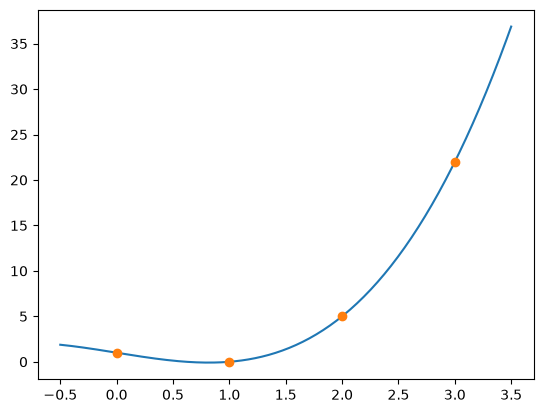

In [29]:
A = np.array([
    [3, 2, -1],
    [-1, 4, 2],
    [2, -1, 5],
])

b = np.array([
    [4],
    [10],
    [23]
])

x = np.linalg.solve(A, b)

print(A @ x - b)

C = np.array([
    [1, 0, 0, 0],
    [1, 1, 1, 1],
    [1, 2, 4, 8],
    [1, 3, 9, 27],
])

y = np.array([
    [1.],
    [0.],
    [5.],
    [22.],
])

c = np.linalg.solve(C, y)

print(C @ c -y)

xf = np.linspace(-.5, 3.5, 200)

p = c[0] + c[1] * xf + c[2] * xf**2 + c[3] * xf**3

plt.plot(xf, p)
plt.plot([0, 1, 2, 3], [1., 0., 5., 22.], "o")

plt.show()

### Solving a nonlinear equation: Newton–Raphson

One way to solve a nonlinear equation $g(x) = 0$ is the **Newton–Raphson** method. It is
*iterative*: you repeat the same operation until the answer stops changing. It starts from a first
guess $x_0$ and repeats

$$x_{k+1} = x_k - \frac{g(x_k)}{g'(x_k)}.$$

In a picture: draw the tangent to $g$ at $x_k$. The point where it crosses the horizontal axis is $x_{k+1}$.

**Exercise 2.2 — Newton–Raphson, and how fast it converges.**

Compute $\sqrt{2}$ by solving $g(x) = x^2 - 2 = 0$ with $g'(x) = 2x$, starting from $x_0 = 1$.

1. Make room for the results first: `iterates = np.zeros(11)`, an array of 11 zeros. Put the
   starting value in `iterates[0]`, then run 10 iterations, writing each new value into
   `iterates[k+1]`.
2. Compute all the errors at once with `errors = np.abs(iterates - np.sqrt(2))`. This is one line
   for the whole array, with no loop. Print each iterate next to its error.
3. Draw the errors against the step number $k$ with **`plt.semilogy`**. This puts a logarithmic
   scale on the $y$-axis, which is the usual way to look at an error that becomes small very fast.
   Draw only the **first 5 points**: after that the error is zero or almost zero, and a logarithmic
   axis cannot show a zero.
4. Look at the printed errors: roughly how many correct digits do you gain per iteration?

💡 *Hint: inside the loop, `iterates[k+1] = iterates[k] - g(iterates[k]) / g_prime(iterates[k])`.
Do not call the loop variable `x`: you already used that name for a grid earlier.*

💡 *Hint:
For the plot, `plt.semilogy(range(5), errors[:5], marker="o")`.*

(1.0, 0.41421356237309515)
(1.5, 0.08578643762690485)
(1.4166666666666667, 0.002453104293571595)
(1.4142156862745099, 2.1239014147411694e-06)
(1.4142135623746899, 1.5947243525715749e-12)
(1.4142135623730951, 0.0)
(1.414213562373095, 2.220446049250313e-16)
(1.4142135623730951, 0.0)
(1.414213562373095, 2.220446049250313e-16)
(1.4142135623730951, 0.0)
(1.414213562373095, 2.220446049250313e-16)


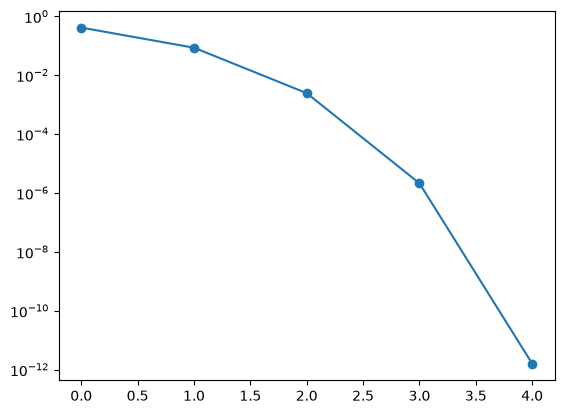

In [30]:
N = 10

iterates = np.zeros(N+1)

iterates[0] = 1

for i in range(N):
    iterates[i+1] = iterates[i] - (iterates[i]**2-2)/(2*iterates[i])

errors = np.abs(iterates - np.sqrt(2))
print(*[(float(iterates[k]), float(errors[k])) for k in range(N+1)], sep = "\n")
plt.semilogy(range(5), errors[:5], marker="o")

plt.show()

---
## Part 3 — Differentiation and integration

Most of the time you do not have a formula for the quantity you study. You have its **values on a
grid**, from a measurement or from a simulation, and you still need its derivative.

Start from the definition you already know:

$$u'(x) = \lim_{h \to 0} \frac{u(x+h) - u(x)}{h}.$$

A computer cannot take a limit. But it does not need to. Your points are already separated by a
small distance $h$, so you simply **stop before the limit** and use that $h$:

$$u'(x) \approx \frac{u(x+h) - u(x)}{h}.$$

This is called the **forward difference**. On a drawing, it is the slope of the straight line
through the two points $(x, u(x))$ and $(x+h, u(x+h))$.

That is the whole idea. The rest of this part asks how good this approximation is, whether we can
do better, and then uses the very same slices to compute an **integral**.

### The tool: slicing

A finite difference is a difference between two *neighbouring values* of an array. In NumPy you take
two slices of the array, shifted by one position, and you subtract them. There is no loop. The cell
below shows what the two slices contain.

In [31]:
u = np.array([0, 10, 40, 90, 160, 250])

print("u        =", u)
print("u[1:]    =", u[1:])     # everything except the FIRST entry
print("u[:-1]   =", u[:-1])    # everything except the LAST entry
print("differences:", u[1:] - u[:-1])   # each entry minus its left neighbour

# Both slices have 5 values, one less than u: there are 5 gaps between 6 points.
print(u.shape, u[1:].shape, (u[1:] - u[:-1]).shape)

u        = [  0  10  40  90 160 250]
u[1:]    = [ 10  40  90 160 250]
u[:-1]   = [  0  10  40  90 160]
differences: [10 30 50 70 90]
(6,) (5,) (5,)


**Exercise 3.1 — the forward difference.**

Take $u(x) = \sin(x)$ on $[0, 2\pi]$. Here you know the exact answer, $u'(x) = \cos(x)$, so you can
measure how good your approximation is.

1. Build a grid `x = np.linspace(0, 2*np.pi, 20)` and the samples `u = np.sin(x)`. Get the spacing
   as `h = x[1] - x[0]`.
2. Compute the forward difference `du_forward = (u[1:] - u[:-1]) / h`, in one line, no loop.

   As in the cell above, you get **one value per gap**: 19 values for 20 points. Each value uses
   one point and its right neighbour. So it approximates $u'$ at the **left** point of the gap.
   These left points are `x[:-1]`.
3. Draw the two things on one figure: the exact derivative $\cos(x)$ as a smooth curve, and your
   `du_forward` as markers placed at `x[:-1]`. Add a legend.
4. Print the largest error, `np.max(np.abs(du_forward - np.cos(x[:-1])))`.

💡 *Hint: for the smooth curve use a second, finer grid, for example
`xf = np.linspace(0, 2*np.pi, 400)`, and plot `np.cos(xf)`. Keep `x` for the markers.*

💡 *Hint: if you get "operands could not be broadcast together", your two arrays have different
lengths. Print their `.shape` and check that you compare `du_forward` with `np.cos(x[:-1])`, not
with `np.cos(x)`.*

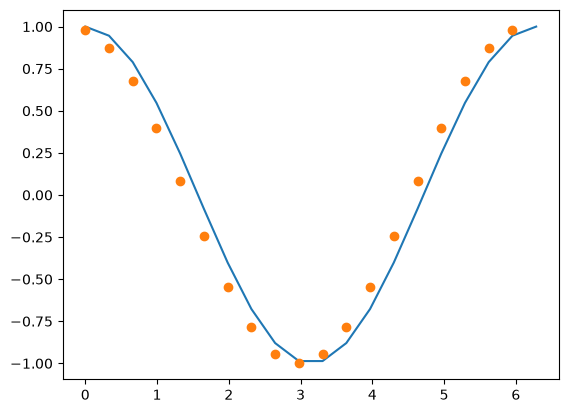

In [32]:
x = np.linspace(0, 2*np.pi, 20)
u = np.sin(x)
h = x[1]-x[0]

du_forward = (u[1:]-u[:-1])/h

du_exact = np.cos(x)

plt.plot(x, du_exact)
plt.plot(x[:-1], du_forward, "o")

plt.show()

### The centred difference

The forward difference uses the point on the right of $x$. The **centred difference** uses both
neighbours:

$$u'(x_i) \approx \frac{u_{i+1} - u_{i-1}}{2h}.$$

In code this is `(u[2:] - u[:-2]) / (2*h)`.

**Exercise 3.2 — the centred difference.**

Keep the same `x`, `u` and `h` as in Exercise 3.1.

1. Compute `du_centred = (u[2:] - u[:-2]) / (2*h)`.

   This time each value uses the point on the **left** and the point on the **right**, so it
   approximates $u'$ at the point in the middle. You get 18 values, placed at the inside points
   `x[1:-1]`. The first and the last point of the grid have no neighbour on one side, so they are
   left out.
2. Draw one figure with three things on it: the exact $\cos(x)$ as a smooth curve, `du_forward` as
   markers at `x[:-1]`, and `du_centred` as markers at `x[1:-1]`. Use a different marker for each.
3. Print the largest error of each one. Which is the better approximation, and by roughly what
   factor?

💡 *Hint: `'ro'` gives red circles and `'bs'` gives blue squares. The largest error of the centred
difference is `np.max(np.abs(du_centred - np.cos(x[1:-1])))` — note `x[1:-1]`, not `x[:-1]`.*

0.16478292359842434 0.017879785825025918


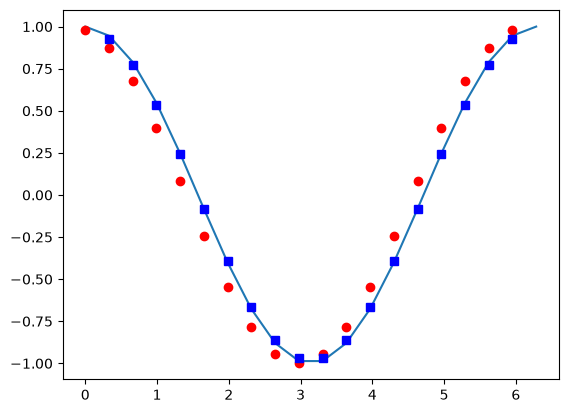

In [33]:
du_centred = (u[2:] - u[:-2])/(2*h)

plt.plot(x, du_exact)
plt.plot(x[:-1], du_forward, "ro")
plt.plot(x[1:-1], du_centred, "bs")

print(np.max(np.abs(du_exact[:-1] - du_forward)), np.max(np.abs(du_exact[1:-1]-du_centred)))

### Going the other way: integration

The same two slices also give you the **integral**. Think of $\int_a^b u(x)\,dx$ as the area under
the curve. Between two neighbouring points the curve is almost a straight line, so that piece of
area is a **trapezoid**: its two parallel sides are $u_i$ and $u_{i+1}$, and its width is $h$.

$$\int_a^b u(x)\,dx \;\approx\; \sum_{i} \frac{u_i + u_{i+1}}{2}\,h$$

This is called the **trapezoid rule**. Notice that you need the same two slices as before, `u[1:]`
and `u[:-1]` — you simply **add** them instead of subtracting them.

**Exercise 3.3 — the trapezoid rule.**

Take $u(x) = \sin(x)$ on $[0, \pi]$ this time. You know the exact answer:
$\int_0^{\pi}\sin(x)\,dx = 2$.

1. Build a new grid `xi = np.linspace(0, np.pi, 20)`, the samples `ui = np.sin(xi)`, and the
   spacing `hi = xi[1] - xi[0]`.
2. Compute the trapezoid rule in **one line**, with slicing and `np.sum`, no loop. Print it next to
   the exact value 2, and print the error.
3. NumPy has this built in: compare your result with `np.trapezoid(ui, xi)`. They should be equal.
4. Do it again with 200 points instead of 20. The grid is 10 times finer — by roughly what factor
   does the error go down?

💡 *Hint for step 2: `np.sum((ui[1:] + ui[:-1]) / 2) * hi`.*

💡 *Hint for step 3: in older code you will see `np.trapz`. That name was removed in NumPy 2, so it
now raises an error. The function is called `np.trapezoid`.*

In [34]:
xi = np.linspace(0, np.pi, 200)

ui = np.sin(xi)
hi = xi[1]-xi[0]

intu = np.sum((ui[1:] + ui[:-1]) * hi / 2)

print(intu, abs(intu-2))

print(intu ==np.trapezoid(ui, xi))

1.999958462137331 4.15378626690277e-05
False


---
## Going further — if you have finished early

Two extra topics, if you finish Part 3 early. The first uses only what you have seen in this
notebook. The second uses SciPy.

### A. A quick look at two-dimensional plots

Until now every function had one variable. A function of two variables $f(x,y)$ is computed on a
**grid** of points $(x_i, y_j)$. `np.meshgrid` builds that grid from two ordinary arrays.

If `x` has $m$ values and `y` has $n$ values, then `X, Y = np.meshgrid(x, y)` gives you two arrays
of shape $n \times m$. At each position of the grid, `X` holds the $x$ coordinate and `Y` holds the
$y$ coordinate. You can then compute $f$ on the whole grid at once, as you did with one variable.

In [35]:
x2 = np.linspace(-3, 3, 200)
y2 = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(x2, y2)          # two 200x200 arrays of coordinates

print(x2.shape, X.shape, Y.shape)

Z = np.sin(X) * np.cos(Y)           # f(x,y) = sin(x)cos(y), on the whole grid, no loop
print(Z.shape)

(200,) (200, 200) (200, 200)
(200, 200)


`plt.pcolormesh` draws a scalar field using colours. Always add a `colorbar`. Without it, the reader
cannot know what value each colour represents.

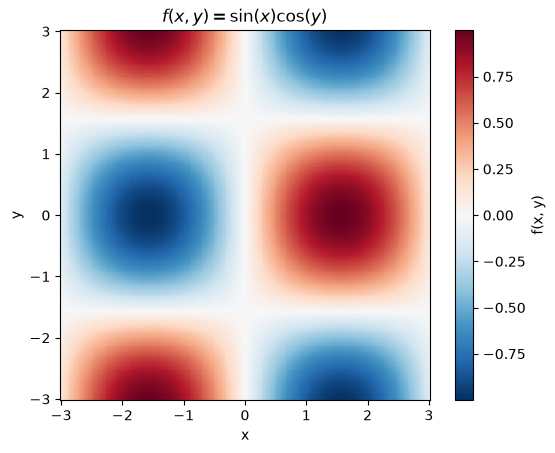

In [36]:
plt.figure()
plt.pcolormesh(X, Y, Z, shading="auto", cmap="RdBu_r")
plt.colorbar(label="f(x, y)")
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"$f(x,y) = \sin(x)\cos(y)$")
plt.gca().set_aspect("equal")
plt.show()

For a **vector** field, such as a velocity, a force or a gradient, `plt.quiver` draws one arrow at
each point of the grid. Here is the rotational field

$$\mathbf{v}(x,y) = (-y,\; x),$$

which rotates around the origin. Use far fewer points than for `pcolormesh`: if the arrows overlap,
you cannot read the figure.

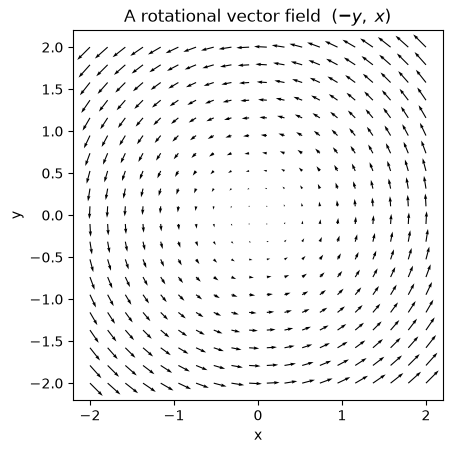

In [37]:
xc = np.linspace(-2, 2, 20)         # 20 points per direction, not 200
yc = np.linspace(-2, 2, 20)
Xc, Yc = np.meshgrid(xc, yc)

Uc = -Yc       # the x-component of the field
Vc =  Xc       # the y-component

plt.figure()
plt.quiver(Xc, Yc, Uc, Vc)
plt.xlabel("x")
plt.ylabel("y")
plt.title(r"A rotational vector field  $(-y,\; x)$")
plt.gca().set_aspect("equal")
plt.show()

These two commands cover most two-dimensional figures. Use `pcolormesh` for a scalar field, such as
a temperature or a pressure. Use `quiver` for a vector field, such as a velocity. They are often drawn
together. Try it: put the `quiver` arrows on top of a `pcolormesh` of $\sqrt{x^2+y^2}$.

### B. Solving an initial value problem with SciPy

In Exercise 2.1 you wrote the matrix of a linear system yourself. Most of the time you do not
have to. **SciPy** has a
solver, and you only have to write the equation.

`solve_ivp` integrates a system of first-order equations

$$\frac{dX}{dt} = f(t, X)$$

starting from a given value at $t = 0$. A second-order equation becomes a system of two first-order
equations, in the usual way. Take a mass on a spring with friction:

$$\ddot{u} + \zeta\,\dot{u} + \lambda\,u = 0.$$

Put $X_0 = u$ (the position) and $X_1 = \dot{u}$ (the velocity). Then

$$\dot{X_0} = X_1, \qquad \dot{X_1} = -\lambda X_0 - \zeta X_1.$$

You give this to `solve_ivp` as a function. Nothing else is needed.

In [38]:
from scipy.integrate import solve_ivp

def oscillator(t, X):
    lam, zeta = 2.0, 1.0            # spring constant, friction
    return [X[1],                    # d(position)/dt = velocity
            -lam * X[0] - zeta * X[1]]   # d(velocity)/dt

t_eval = np.linspace(0, 10, 500)     # the times where we want the answer
solution = solve_ivp(oscillator, [0, 10], [1.0, 0.0], t_eval=t_eval)
#                    the equation   t from 0 to 10   start: position 1, velocity 0

print(solution.t.shape, solution.y.shape)   # 500 times, 2 components

ModuleNotFoundError: No module named 'scipy'

`solution.t` holds the times, `solution.y[0]` the position and `solution.y[1]` the velocity.

In [ ]:
plt.figure()
plt.plot(solution.t, solution.y[0], 'b-', linewidth=2, label="position")
plt.plot(solution.t, solution.y[1], 'r--', linewidth=2, label="velocity")
plt.xlabel("time")
plt.ylabel("u(t)")
plt.title("A mass on a spring, with friction")
plt.legend()
plt.grid(True)
plt.show()

The oscillation gets smaller and smaller: this is the friction.

Change `zeta` to `0.0` and run the two cells again. Without friction the oscillation never stops.
Try `zeta = 3.0` as well: the mass returns to zero without oscillating at all.

---
## Where you are now

You can now open and run a notebook. You can write simple Python and build NumPy arrays. You can
draw a clear figure, solve linear and nonlinear equations, and compute a derivative and an integral
from values on a grid. This is enough to follow a lecture or a TP that uses Python.

**Good habits.** Run your notebook from the top before you submit it. Give your variables names
that say what they contain. Put a title and axis labels on every figure. Check the shapes, the units and the orders of
magnitude. Read the error messages: they usually tell you both the line and the problem. And check a
numerical result before you trust it.


**Next session:** SciPy, Pandas, and
a guided mini-project on a real data file.